## Reverberation Mapping

This notebook measures the broad H$\beta$ time lag of the Seyfert galaxy **MCG+08-11-011** ($z=0.0205$) with **EzTaoX**, and tests whether the broad-line response is a pure time delay or is also smoothed.

The data are from the 2014 MDM Observatory reverberation-mapping campaign:

> Fausnaugh, M. M., Grier, C. J., Bentz, M. C., et al. 2017, *ApJ*, 840, 97, "Reverberation Mapping of Optical Emission Lines in Five Active Galaxies" ([ADS](https://ui.adsabs.harvard.edu/abs/2017ApJ...840...97F))

The light curves are public through VizieR, catalog [`J/ApJ/840/97`](https://vizier.cds.unistra.fr/viz-bin/VizieR?-source=J/ApJ/840/97). The campaign observed MCG+08-11-011 nearly every night for about four months. The continuum light curve combines spectroscopic and photometric measurements from several telescopes, and the H$\beta$ light curve comes from the MDM spectra. This object is well suited to testing the shape of the broad-line response: the lag (about two weeks) is many times longer than the cadence, and the continuum varies on timescales comparable to the lag.

We fit the continuum and H$\beta$ jointly with GP models that share one latent damped random walk (DRW):

1. a **pure shift**: H$\beta$ is a delayed, rescaled copy of the continuum (`MultiVarModel` with a lag);
2. an **Erlang transfer function**: H$\beta$ is the continuum convolved with a smooth, causal response (`MixedBLRKernel`).

We sample both with NUTS and compare them.

### 0. Setup

Sections 1–5 use the standard `MultiVarModel` lag fit, which runs with the released versions of `eztaox` and `tinygp`. Section 6 uses `MixedBLRKernel`, which is not time-reversible and needs the GitHub version of `tinygp` until its next release:

```
pip install -U "git+https://github.com/dfm/tinygp"
```

The light curves ship with this notebook in `data/MCG+08-11-011_MDM2014.csv`, so no internet access is needed. The cell below prints the versions used.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update(
    {
        "text.usetex": False,
        "axes.labelsize": 20,
        "figure.labelsize": 18,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "figure.constrained_layout.wspace": 0,
        "figure.constrained_layout.hspace": 0,
        "figure.constrained_layout.h_pad": 0,
        "figure.constrained_layout.w_pad": 0,
        "axes.linewidth": 1.2,
    }
)

import jax
import jax.numpy as jnp

# you should always set this
jax.config.update("jax_enable_x64", True)

import numpyro, tinygp, eztaox

print(
    f"eztaox {eztaox.__version__} | tinygp {tinygp.__version__} | numpyro {numpyro.__version__} | jax {jax.__version__}"
)

eztaox 0.2.0 | tinygp 0.3.2.dev17+g103b634a6 | numpyro 0.19.0 | jax 0.6.2


/Users/colinburke/miniforge3/envs/jaxcpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1. The MDM 2014 light curves

The light curves are taken from VizieR catalog `J/ApJ/840/97` (Fausnaugh et al. 2017): table `lccont` (continuum flux density near 5100 Å, with the telescope of each measurement) and table `lclines` (broad-line fluxes, including H$\beta$). For convenience, the MCG+08-11-011 rows are saved in `data/MCG+08-11-011_MDM2014.csv`, with columns `kind` (`cont` or `hbeta`), `HJD` (HJD $-$ 2450000), `flux`, `err`, and `tel` (telescope). Please cite Fausnaugh et al. (2017) if you use these data.

In [2]:
data = pd.read_csv("data/MCG+08-11-011_MDM2014.csv", comment="#")
cont = data[data["kind"] == "cont"].sort_values("HJD")
hb = data[data["kind"] == "hbeta"].sort_values("HJD")
print(
    f"continuum: {len(cont)} epochs; telescopes {cont['tel'].value_counts().to_dict()}"
)
print(f"Hbeta:     {len(hb)} epochs")

continuum: 190 epochs; telescopes {'MDM': 82, 'WC18': 50, 'CrAO': 42, 'WMO': 12, 'WIRO': 4}
Hbeta:     86 epochs


We convert both light curves to fractional flux variations, $y = F/\mathrm{median}(F) - 1$. Times are HJD $-$ 2450000, as in the catalog.

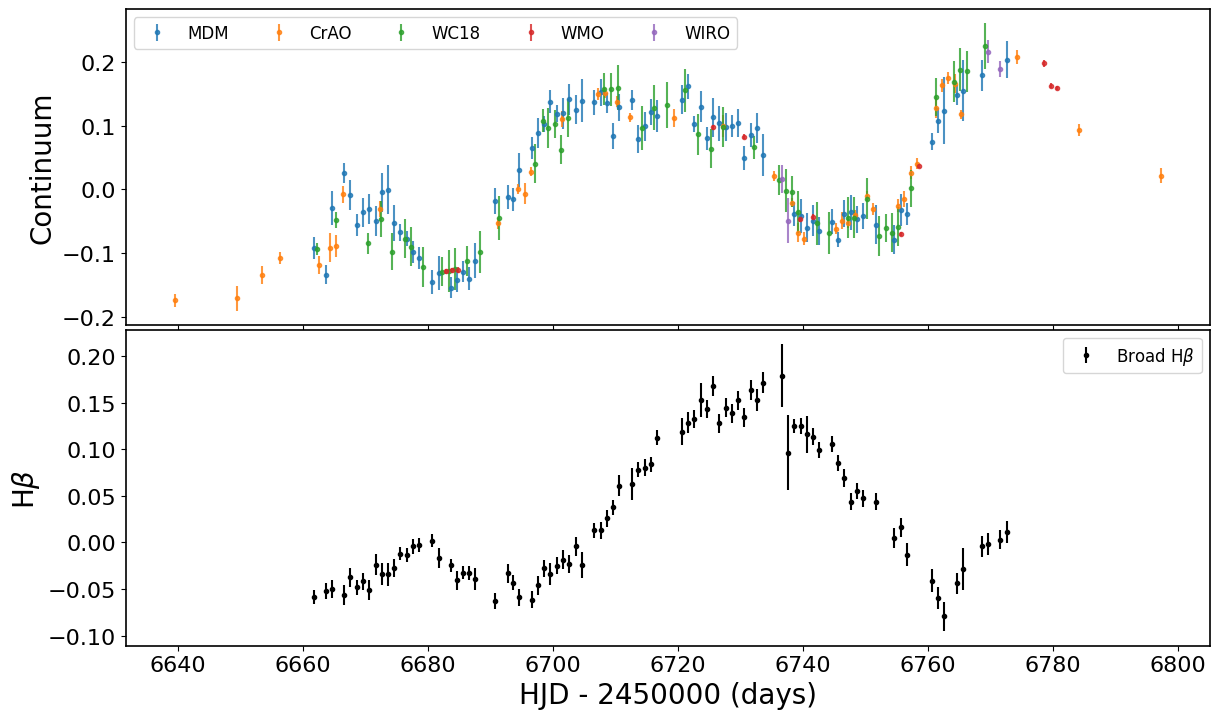

In [3]:
z = 0.0205
TELESCOPES = ["MDM", "CrAO", "WC18", "WMO", "WIRO"]

f0_cont, f0_hb = np.median(cont["flux"]), np.median(hb["flux"])
t_cont, y_cont, e_cont = (
    cont["HJD"].values,
    cont["flux"].values / f0_cont - 1,
    cont["err"].values / f0_cont,
)
t_hb, y_hb, e_hb = (
    hb["HJD"].values,
    hb["flux"].values / f0_hb - 1,
    hb["err"].values / f0_hb,
)
tel = cont["tel"].values

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
for tname in TELESCOPES:
    sel = tel == tname
    axes[0].errorbar(
        t_cont[sel], y_cont[sel], e_cont[sel], fmt=".", alpha=0.8, label=tname
    )
axes[1].errorbar(t_hb, y_hb, e_hb, fmt=".", color="k", label=r"Broad H$\beta$")
axes[0].set_ylabel("Continuum")
axes[1].set_ylabel(r"H$\beta$")
axes[1].set_xlabel("HJD - 2450000 (days)")
axes[0].legend(fontsize=12, ncol=5)
axes[1].legend(fontsize=12);

H$\beta$ clearly echoes the continuum about two weeks later, and its light curve looks smoother than the continuum's.

### 2. One continuum band per telescope

The continuum combines several telescopes. Their quoted uncertainties are not calibrated the same way, and small residual flux offsets between telescopes are possible. A quick check: compare each telescope's scatter around a running median with its quoted errors.

In [4]:
running = np.array(
    [np.median(y_cont[max(0, i - 3) : i + 4]) for i in range(y_cont.size)]
)
check = pd.DataFrame({"Tel": tel, "resid": y_cont - running, "err": e_cont})
check.groupby("Tel").agg(
    n=("resid", "size"), scatter=("resid", "std"), median_error=("err", "median")
).round(4)

,n,scatter,median_error
Tel,,,
CrAO,42,0.0260,0.0101
MDM,82,0.0221,0.0212
WC18,50,0.0192,0.0312
WIRO,4,0.0253,0.0199
WMO,12,0.0118,0.0040


Some telescopes scatter much more than their quoted errors, and others less. So we give **each telescope its own continuum band**, with its own mean (offset) and jitter. All continuum bands see the same latent DRW with the same amplitude. H$\beta$ is the last band and is the only one with a lag. EzTaoX handles this directly: bands are just integer labels in `X`.

In [5]:
from eztaox.ts_utils import formatlc

ts = {tname: t_cont[tel == tname] - 0.0 for tname in TELESCOPES}
ys = {tname: y_cont[tel == tname] for tname in TELESCOPES}
es = {tname: e_cont[tel == tname] for tname in TELESCOPES}
ts["hb"], ys["hb"], es["hb"] = t_hb, y_hb, e_hb
band_index = {
    name_: i for i, name_ in enumerate(ts)
}  # continuum bands 0-4, Hbeta band 5
n_band = len(band_index)
HB = band_index["hb"]

t_ref = 6600.0  # subtract a reference time to keep numbers small
X, y, yerr = formatlc({k: v - t_ref for k, v in ts.items()}, ys, es, band_index)

### 3. The pure-shift model

`MultiVarModel` with `has_lag=True` gives each band a time shift and an amplitude relative to the reference band. Here only H$\beta$ should be shifted and rescaled, so we pass small `lag_func` and `amp_scale_func` functions that set the continuum bands to zero lag and unit amplitude. With `zero_mean=False` and `has_jitter=True`, every band gets its own mean and jitter.

**This model treats the lag as a pure time shift**, i.e., a delta-function transfer function. In Section 6 we replace it with an Erlang transfer function, which also smooths the response.

In [6]:
from eztaox.fitter import random_search
from eztaox.kernels.quasisep import Exp
from eztaox.models import MultiVarModel
import numpyro.distributions as dist

m_shift = MultiVarModel(
    X,
    y,
    yerr,
    Exp(scale=50.0, sigma=0.1),
    n_band,
    has_lag=True,
    zero_mean=False,
    has_jitter=True,
    lag_func=lambda p: jnp.zeros(n_band).at[HB].set(p["lag"]),
    amp_scale_func=lambda p: jnp.zeros(n_band).at[HB].set(p["log_amp"]),
)

#### Priors

One function defines the priors for all models. It is the `init_sampler` for the maximum-likelihood search and the `numpyro` model for MCMC.

- Each parameter is a single `numpyro` site with the same name as the model parameter. The DRW parameters are sampled together as `log_kernel_param`. So the maximum-likelihood solution can start NUTS directly.
- All priors are normal (log-normal for scales), so the maximum-likelihood solution is always inside their support.
- The DRW timescale has median 100 days and 1 dex width. The campaign is only four months long, so long timescales are barely constrained, and a flat prior out to thousands of days only slows the sampler.
- The pure-shift lag has a prior of $15 \pm 10$ days; the Erlang mean lag (Section 6) a log-normal prior with median 15 days.
- `log_amp` is the log ratio of the H$\beta$ amplitude to the continuum amplitude.

In [7]:
def priors(lag_name):
    params = {
        "log_kernel_param": numpyro.sample(
            "log_kernel_param", dist.Normal(jnp.log(jnp.array([100.0, 0.1])), 1.0)
        ),
        "log_amp": numpyro.sample("log_amp", dist.Normal(0.0, 1.0)),
        "mean": numpyro.sample("mean", dist.Normal(jnp.zeros(n_band), 0.1)),
        "log_jitter": numpyro.sample(
            "log_jitter", dist.Normal(jnp.full(n_band, jnp.log(0.01)), 2.0)
        ),
    }
    if lag_name == "lag":
        params["lag"] = numpyro.sample("lag", dist.Normal(15.0, 10.0))
    else:
        params["log_lag"] = numpyro.sample("log_lag", dist.Normal(jnp.log(15.0), 1.0))
    return params

### 4. Maximum-likelihood fit and MCMC

`random_search` evaluates the likelihood at many random draws from the priors and refines the best few with L-BFGS-B. We then start NUTS at that solution.

In [8]:
%%time
from numpyro.infer import MCMC, NUTS, init_to_value

best_shift, _ = random_search(
    m_shift, lambda: priors("lag"), jax.random.PRNGKey(0), 3000, 8
)
mcmc_shift = MCMC(
    NUTS(
        lambda m: m.sample(priors("lag")),
        dense_mass=True,
        target_accept_prob=0.9,
        init_strategy=init_to_value(values=best_shift),
    ),
    num_warmup=500,
    num_samples=1000,
    progress_bar=False,
)
mcmc_shift.run(jax.random.PRNGKey(1), m_shift)
mcmc_shift.print_summary()


                         mean       std    median      5.0%     95.0%     n_eff     r_hat
                lag     15.47      0.62     15.64     14.47     16.36    178.53      1.00
            log_amp     -0.34      0.04     -0.33     -0.40     -0.26    640.18      1.00
      log_jitter[0]     -5.26      1.24     -4.85     -6.88     -3.76    231.40      1.00
      log_jitter[1]     -4.56      1.00     -4.25     -5.86     -3.59     82.96      1.02
      log_jitter[2]     -6.39      1.25     -6.22     -8.20     -4.51    698.38      1.00
      log_jitter[3]     -5.37      1.20     -5.09     -7.24     -3.82    299.87      1.00
      log_jitter[4]     -5.38      1.46     -5.15     -7.89     -3.41    620.36      1.00
      log_jitter[5]     -4.01      0.18     -4.00     -4.28     -3.73    544.06      1.00
log_kernel_param[0]      4.58      0.66      4.50      3.59      5.76    812.77      1.00
log_kernel_param[1]     -1.96      0.32     -2.00     -2.49     -1.46    800.16      1.00
         

Check that `r_hat` is close to 1, `n_eff` is a reasonable fraction of the number of samples, and there are no divergences. For a publication-quality result, run several chains (`num_chains`) started from different points and compare them.

### 5. The pure-shift lag

In [9]:
samples_shift = mcmc_shift.get_samples()
lag_shift = np.asarray(samples_shift["lag"])
lo, med, hi = np.percentile(lag_shift, [16, 50, 84])
print(
    f"pure shift: {med:.1f} +{hi - med:.1f} / -{med - lo:.1f} observed-frame days = {med / (1 + z):.1f} rest-frame days"
)

pure shift: 15.6 +0.3 / -0.9 observed-frame days = 15.3 rest-frame days


Compare with the H$\beta$ lag reported by Fausnaugh et al. (2017) for this object, which they measure with cross-correlation and JAVELIN. Small differences are expected from the different methods.

### 6. An Erlang transfer function instead of a pure shift

The broad-line region responds over a range of delays, so a more physical model convolves the continuum with a causal transfer function $\psi(u)$:

$$
\ell(t) = \int_0^\infty \psi(u)\, x(t-u)\, du .
$$

We use an **Erlang** (integer-shape gamma) transfer function, $\psi_K(u) \propto u^{K-1} e^{-Ku/\bar\tau}$, with mean lag $\bar\tau$ and fractional rms width $1/\sqrt{K}$. Because $\psi_K$ is the response of $K$ first-order filters in series, the convolved model stays a small linear state-space model, and the likelihood is still $\mathcal{O}(N)$. The [Photometric Reverberation Mapping](07_PhotometricReverberationMapping.ipynb) tutorial derives this in full. It is implemented in `eztaox.kernels.quasisep.MixedBLRKernel`.

`MixedBLRKernel` models every band as $y_b = c_b\,x(t) + r_b\,\ell(t)$. The continuum and H$\beta$ light curves here are **spectroscopically decomposed**, so there is no line flux in the continuum and no continuum in the line: we set $c_b=1, r_b=0$ for the continuum bands and $c_b=0$ with $r_b$ free for H$\beta$. The free parameters are the same as for the pure shift, with the H$\beta$ response amplitude in place of the shift amplitude and the mean lag $\bar\tau$ in place of the shift.

**Comparing lags.** The pure shift fits a single delay. The Erlang lag is the *mean* (centroid) of a skewed response, whose peak comes earlier, at $(K-1)\bar\tau/K$.

We fit two orders: $K=3$ (a broad response, rms width 58% of the lag) and $K=10$ (a narrower one, 32%).

In [10]:
%%time
from eztaox.kernels.quasisep import MixedBLRKernel

# continuum bands see the driver (c = 1, r = 0); Hbeta sees only the BLR response (c = 0)
models = {"Pure shift": m_shift}
mcmcs = {"Pure shift": mcmc_shift}
for K in (3, 10):
    label = f"Erlang K={K}"
    models[label] = MultiVarModel(
        X,
        y,
        yerr,
        Exp(scale=50.0, sigma=0.1),
        n_band,
        multiband_kernel=lambda params, kernel, K=K: MixedBLRKernel(
            params={
                "lag": jnp.exp(params["log_lag"]),
                "amp_cont": jnp.ones(n_band).at[HB].set(0.0),
                "amp_blr": jnp.zeros(n_band).at[HB].set(jnp.exp(params["log_amp"])),
            },
            kernel=kernel,
            order=K,
        ),
        amp_scale_func=lambda p: jnp.zeros(n_band),
        zero_mean=False,
        has_jitter=True,
    )
    best, _ = random_search(
        models[label], lambda: priors("log_lag"), jax.random.PRNGKey(0), 3000, 8
    )
    mcmcs[label] = MCMC(
        NUTS(
            lambda m: m.sample(priors("log_lag")),
            dense_mass=True,
            target_accept_prob=0.9,
            init_strategy=init_to_value(values=best),
        ),
        num_warmup=500,
        num_samples=1000,
        progress_bar=False,
    )
    mcmcs[label].run(jax.random.PRNGKey(1), models[label])
mcmcs["Erlang K=10"].print_summary()


                         mean       std    median      5.0%     95.0%     n_eff     r_hat
            log_amp     -0.23      0.04     -0.23     -0.30     -0.16   1455.69      1.00
      log_jitter[0]     -6.04      1.28     -5.77     -7.88     -4.10    504.87      1.00
      log_jitter[1]     -3.86      0.28     -3.84     -4.27     -3.43    935.94      1.00
      log_jitter[2]     -6.37      1.27     -6.18     -8.43     -4.58    735.92      1.00
      log_jitter[3]     -6.04      1.34     -5.80     -7.94     -3.99    563.60      1.00
      log_jitter[4]     -5.47      1.47     -5.36     -7.82     -3.13    850.18      1.00
      log_jitter[5]     -4.43      0.18     -4.42     -4.73     -4.15    851.43      1.00
log_kernel_param[0]      4.40      0.67      4.36      3.35      5.47    914.98      1.00
log_kernel_param[1]     -1.95      0.33     -1.98     -2.51     -1.48    924.19      1.00
            log_lag      2.73      0.03      2.73      2.69      2.78   1055.18      1.00
         

#### Comparing the models

All three models have the same number of free parameters, so their maximum log-likelihoods compare directly. We take the maximum over the posterior samples. We also show the H$\beta$ jitter: the extra white noise each model needs to explain the H$\beta$ data, compared with the quoted H$\beta$ errors.

In [11]:
rows, lags = [], {}
for label, mcmc in mcmcs.items():
    s = mcmc.get_samples()  # every sample site is a model parameter
    logl = jax.vmap(models[label].log_prob)(s)
    lag = np.asarray(s["lag"]) if "lag" in s else np.exp(np.asarray(s["log_lag"]))
    lags[label] = lag
    lo, med, hi = np.percentile(lag, [16, 50, 84])
    rows.append(
        {
            "model": label,
            "max log L": float(jnp.max(logl)),
            "lag (d)": f"{med:.1f} +{hi - med:.1f}/-{med - lo:.1f}",
            "Hβ jitter": float(np.median(np.exp(np.asarray(s["log_jitter"])[:, HB]))),
        }
    )
print(f"median Hβ error: {np.median(e_hb):.4f}")
pd.DataFrame(rows).round(4)

median Hβ error: 0.0099


,model,max log L,lag (d),Hβ jitter
0,Pure shift,594.2784,15.6 +0.3/-0.9,0.0183
1,Erlang K=3,598.0380,16.2 +0.6/-0.6,0.0144
2,Erlang K=10,614.9581,15.4 +0.4/-0.4,0.0121


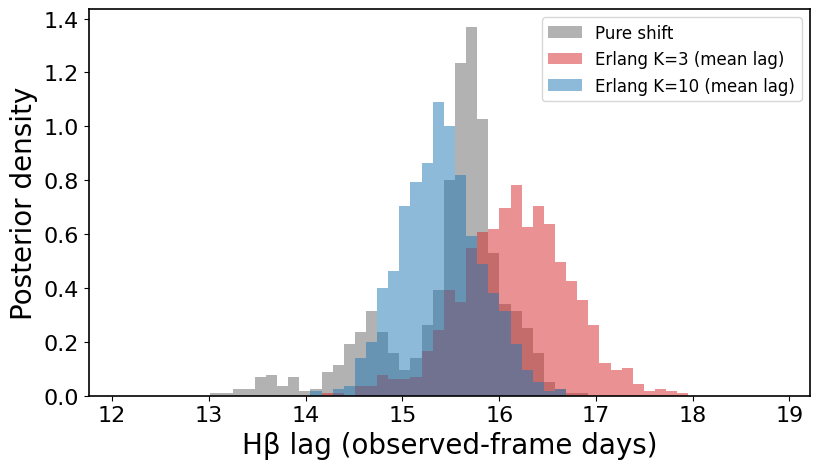

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
bins = np.linspace(
    min(v.min() for v in lags.values()) - 1, max(v.max() for v in lags.values()) + 1, 60
)
for (label, lag), color in zip(lags.items(), ["0.4", "tab:red", "tab:blue"]):
    ax.hist(
        lag,
        bins=bins,
        density=True,
        alpha=0.5,
        color=color,
        label=label if label == "Pure shift" else f"{label} (mean lag)",
    )
ax.set_xlabel("Hβ lag (observed-frame days)")
ax.set_ylabel("Posterior density")
ax.legend(fontsize=12);

#### Conditional predictions

Finally, we condition each model on all the data at its median posterior parameters and predict the H$\beta$ light curve. The pure shift copies the continuum's short-timescale wiggles into H$\beta$, and the H$\beta$ data don't show them. The bottom panel shows the H$\beta$ residuals in units of the quoted errors.

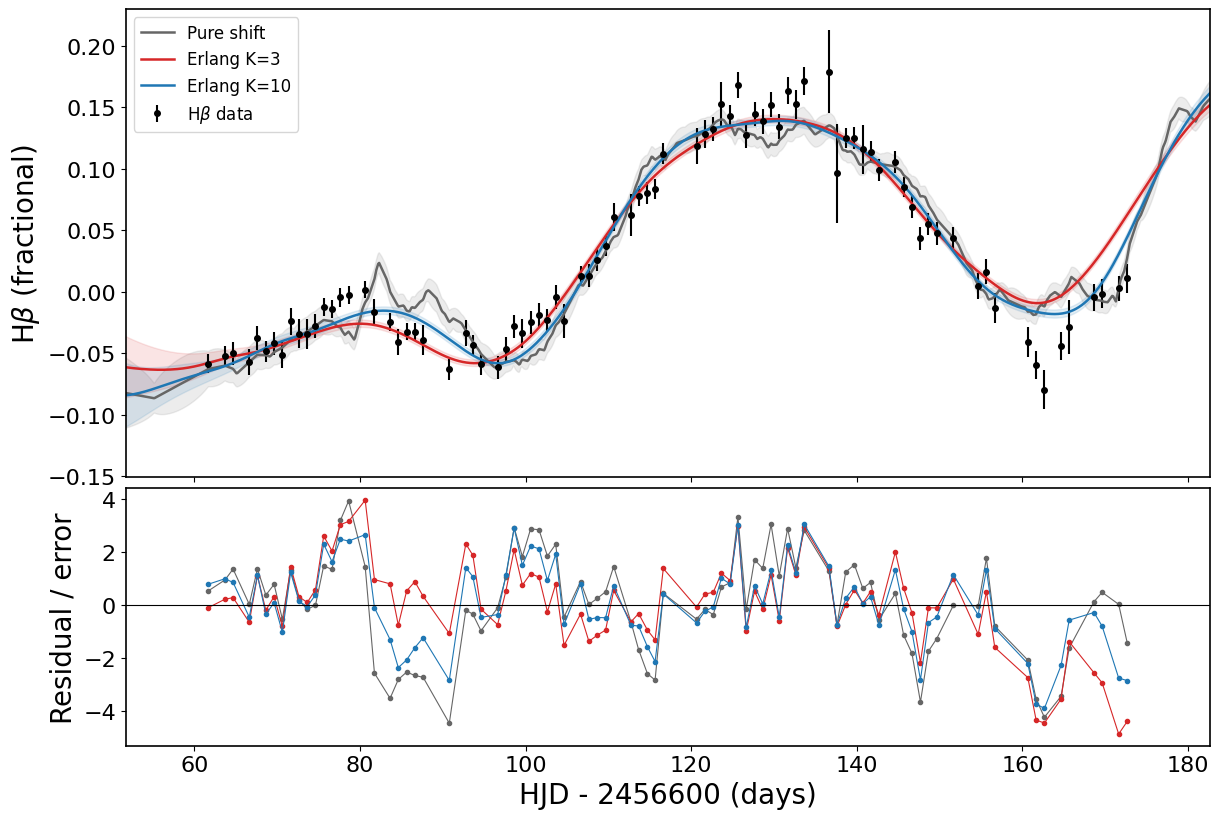

In [13]:
t_grid = jnp.linspace(X[0].min() - 5, X[0].max() + 5, 1500)
hb_mask = np.asarray(X[1]) == HB
fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 8),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [1, 0.55]},
)
axes[0].errorbar(
    np.asarray(X[0])[hb_mask],
    np.asarray(y)[hb_mask],
    np.asarray(yerr)[hb_mask],
    fmt="o",
    ms=4,
    color="k",
    label=r"H$\beta$ data",
)
for (label, mcmc), color in zip(mcmcs.items(), ["0.4", "tab:red", "tab:blue"]):
    s = mcmc.get_samples()
    p = {k: jnp.median(v, axis=0) for k, v in s.items()}
    mu, sd = models[label].pred(p, (t_grid, jnp.full(t_grid.shape, HB)))
    axes[0].plot(t_grid, mu, color=color, lw=1.8, label=label)
    axes[0].fill_between(t_grid, mu - sd, mu + sd, color=color, alpha=0.12)
    mu_d, _ = models[label].pred(p, (X[0][hb_mask], jnp.full(hb_mask.sum(), HB)))
    resid = (np.asarray(y)[hb_mask] - np.asarray(mu_d)) / np.asarray(yerr)[hb_mask]
    axes[1].plot(
        np.asarray(X[0])[hb_mask], resid, "o-", ms=3, lw=0.8, color=color, label=label
    )
axes[0].set_ylabel(r"H$\beta$ (fractional)")
axes[0].legend(fontsize=12, loc="upper left")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_ylabel("Residual / error")
axes[1].set_xlabel(f"HJD - {2450000 + t_ref:.0f} (days)")
axes[0].set_xlim(
    np.asarray(X[0])[hb_mask].min() - 10, np.asarray(X[0])[hb_mask].max() + 10
);

### 7. Next steps

- **Response width.** Change the Erlang order to test which response width the data prefer, or compare more orders by their maximum likelihood.
- **Other lines and objects.** The same catalog has H$\gamma$ and He II light curves (`lclines`) and four more AGN from the same campaign. Wider or longer-lag responses show the transfer-function shape more clearly.
- **Remaining residuals.** The H$\beta$ residuals in the last plot are correlated in time for all models. A line response that is not exactly proportional to the continuum, or a slow drift between them, would show up this way; a different transfer-function shape would not remove it.
- **Photometric data.** When a band contains both continuum and line, see the [Photometric Reverberation Mapping](07_PhotometricReverberationMapping.ipynb) tutorial.
- **Nested sampling.** For the most reliable results, use nested sampling (e.g., `numpyro.contrib.nested_sampling.NestedSampler`) instead of NUTS. It explores multimodal lag posteriors more robustly and gives the Bayesian evidence for comparing models (e.g., pure shift vs. Erlang, or different Erlang orders). It can be much slower, especially with many nuisance parameters.